# 03 — Xây dựng đồ thị possession (Graph Construction)

## 1. Mục tiêu
Notebook này giải thích và trực quan hóa **Bước 3** trong quy trình XAI-Football:
- Chuyển đổi chuỗi đường chuyền trong possession thành đồ thị có hướng không gian - thời gian (spatio-temporal possession graph).
- Đỉnh (Nodes): Cầu thủ tham gia possession, đặc trưng gồm tọa độ trung bình, số lần chuyền/nhận, và vai trò (one-hot role: GK, DF, MF, FW).
- Cạnh (Edges): Từng đường chuyền thực tế, đặc trưng gồm tọa độ bắt đầu/kết thúc, độ dài, góc chuyền (sin, cos), thứ tự thời gian và độ cao chuyền.
- Cắt đồ thị tại thời điểm cú sút đầu tiên (`truncate_at_first_shot: true`) để loại bỏ rò rỉ thông tin sau khi sút.
- Phân tích số lượng đồ thị được tạo và bị loại.
- Kiểm tra tọa độ nằm ngoài sân (StatsBomb đôi khi ghi x > 120) — đã được kẹp về biên sân.
- Trực quan hóa một đồ thị possession thực tế trên sân cỏ.

## 2. Vị trí của bước trong pipeline
Đây là **Bước 3 — Dựng đồ thị (`scripts/04_build_graphs.py`, `src/xai_football/graphs/`)**.

In [1]:
import json
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Gốc repo: chạy được cả khi kernel đứng ở notebooks/ (mặc định của Jupyter/nbconvert)
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs").is_dir())
figures_dir = REPO_ROOT / "results" / "figures" / "official"
figures_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 150

## 3. Input và nguồn dữ liệu
- File đồ thị PyG: `data/processed/official/graphs.pt`
- Index đồ thị: `data/processed/official/graph_index.parquet`
- Danh sách đặc trưng: `data/processed/official/feature_names.json`
- Bảng kiểm tra toàn vẹn đồ thị: `results/tables/official/graph_checks.csv`

## 4. Config/script/module sử dụng
- Cấu hình: `configs/graph.yaml`
- Script: `scripts/04_build_graphs.py`
- Module: `src/xai_football/graphs/build.py`, `dataset.py`, `features.py`.

## 5. Các bước xử lý & Kiểm tra dữ liệu đầu vào

In [2]:
index_path = REPO_ROOT / "data" / "processed" / "official" / "graph_index.parquet"
feature_names_path = REPO_ROOT / "data" / "processed" / "official" / "feature_names.json"
checks_path = REPO_ROOT / "results" / "tables" / "official" / "graph_checks.csv"

for p in [index_path, checks_path]:
    if not p.exists():
        raise FileNotFoundError(f"Thiếu file: {p}. Vui lòng chạy: python scripts/04_build_graphs.py --config configs/data.yaml")

df_index = pd.read_parquet(index_path)
df_checks = pd.read_csv(checks_path)

with open(feature_names_path, encoding="utf-8") as f:
    feat_names = json.load(f)

print(f"Tổng số đồ thị đã tạo: {len(df_index):,}")
print("Đặc trưng Node:", feat_names.get("node_features"))
print("Đặc trưng Edge:", feat_names.get("edge_features"))

Tổng số đồ thị đã tạo: 45,047
Đặc trưng Node: ['role_GK', 'role_DF', 'role_MF', 'role_FW', 'mean_x', 'mean_y', 'n_passes_made', 'n_passes_received']
Đặc trưng Edge: ['start_x', 'start_y', 'end_x', 'end_y', 'length', 'angle_sin', 'angle_cos', 'height_ground', 'height_low', 'height_high', 'order_in_possession', 'elapsed_minutes']


## 6. Kết quả và cách diễn giải
### 6.1. Phân bố số lượng Đỉnh (Nodes) và Cạnh (Edges) trong tập đồ thị

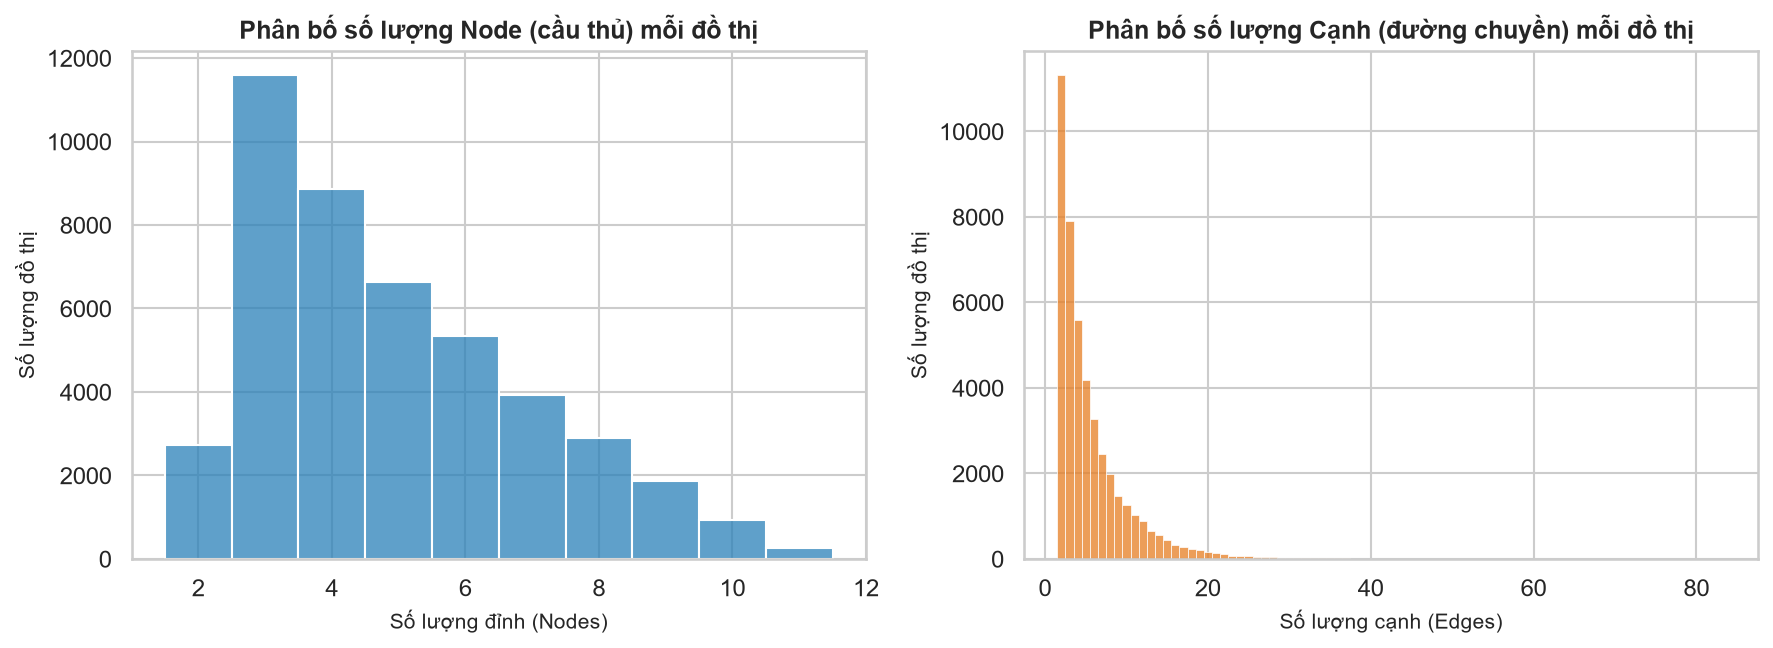

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df_index["n_nodes"], bins=range(2, 12), discrete=True, color="#2980b9", ax=axes[0])
axes[0].set_title("Phân bố số lượng Node (cầu thủ) mỗi đồ thị", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Số lượng đỉnh (Nodes)", fontsize=10)
axes[0].set_ylabel("Số lượng đồ thị", fontsize=10)

sns.histplot(df_index["n_edges"], bins=range(2, 25), discrete=True, color="#e67e22", ax=axes[1])
axes[1].set_title("Phân bố số lượng Cạnh (đường chuyền) mỗi đồ thị", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Số lượng cạnh (Edges)", fontsize=10)
axes[1].set_ylabel("Số lượng đồ thị", fontsize=10)

plt.tight_layout()
plt.savefig(figures_dir / "03_graph_node_edge_dist.png", dpi=300)
plt.savefig(figures_dir / "03_graph_node_edge_dist.svg")
plt.show()

### 6.2. Trực quan hóa một Possession Graph thực tế trên sân cỏ (Pitch Visualization)

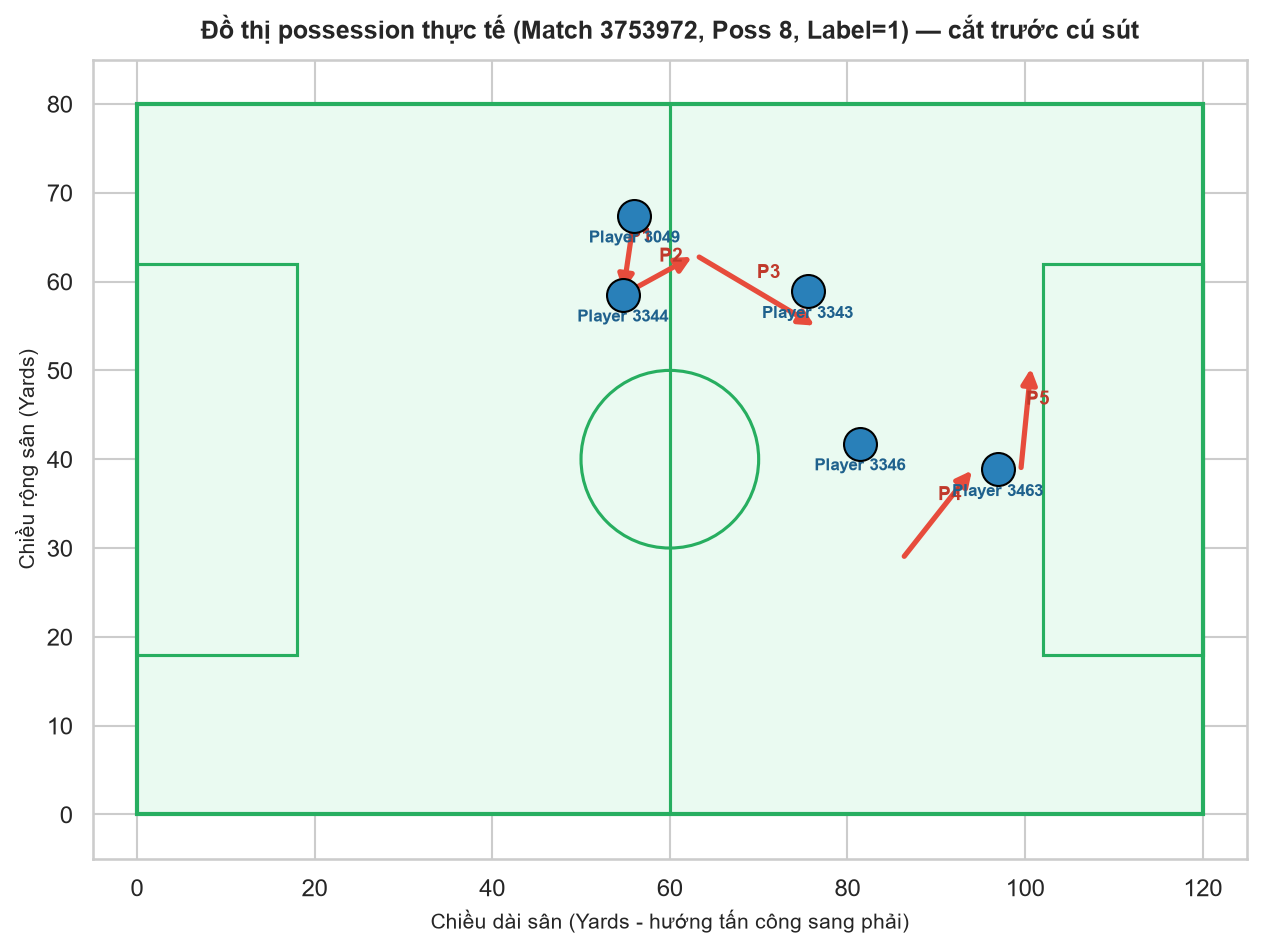

In [4]:
# Lấy một possession mẫu có nhãn dương (y=1) và vẽ ĐÚNG những đường chuyền nằm trong đồ thị,
# tức là đã cắt trước cú sút đầu tiên (truncate_at_first_shot) giống scripts/04_build_graphs.py.
sample_pos = df_index[df_index["y"] == 1].iloc[0]
match_id = int(sample_pos["match_id"])
poss_id = int(sample_pos["possession_id"])

interim = REPO_ROOT / "data" / "interim" / "official"
df_passes = pd.read_parquet(interim / "possession_events.parquet")
df_poss = pd.read_parquet(interim / "possessions.parquet")
first_shot = df_poss[(df_poss["match_id"] == match_id) & (df_poss["possession_id"] == poss_id)]["first_shot_index"].iloc[0]
sample_passes = df_passes[(df_passes["match_id"] == match_id) & (df_passes["possession_id"] == poss_id)].sort_values("event_index")
if pd.notna(first_shot):
    sample_passes = sample_passes[sample_passes["event_index"] < first_shot]
assert len(sample_passes) == int(sample_pos["n_edges"]), "Số cạnh vẽ ra phải bằng số cạnh của đồ thị"
# Kẹp tọa độ về khung 120 x 80 giống features.clip_to_pitch (đồ thị dùng tọa độ đã kẹp)
sample_passes = sample_passes.copy()
sample_passes[["start_x", "end_x"]] = sample_passes[["start_x", "end_x"]].clip(0, 120)
sample_passes[["start_y", "end_y"]] = sample_passes[["start_y", "end_y"]].clip(0, 80)

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.set_xlim(-5, 125)
ax.set_ylim(-5, 85)
ax.add_patch(patches.Rectangle((0, 0), 120, 80, linewidth=2, edgecolor="#27ae60", facecolor="#eafaf1"))
ax.plot([60, 60], [0, 80], color="#27ae60", linewidth=1.5)
ax.add_patch(patches.Circle((60, 40), 10, linewidth=1.5, edgecolor="#27ae60", facecolor="none"))
ax.add_patch(patches.Rectangle((0, 18), 18, 44, linewidth=1.5, edgecolor="#27ae60", facecolor="none"))
ax.add_patch(patches.Rectangle((102, 18), 18, 44, linewidth=1.5, edgecolor="#27ae60", facecolor="none"))

for idx, (_, row) in enumerate(sample_passes.iterrows()):
    sx, sy, ex, ey = row["start_x"], row["start_y"], row["end_x"], row["end_y"]
    ax.annotate("", xy=(ex, ey), xytext=(sx, sy), arrowprops=dict(arrowstyle="-|>", color="#e74c3c", lw=2.5, mutation_scale=15))
    ax.text((sx + ex) / 2, (sy + ey) / 2 + 1.5, f"P{idx+1}", color="#c0392b", fontweight="bold", fontsize=9)

# Vị trí đỉnh = trung bình mọi lần chạm bóng (chuyền đi + nhận), đúng như đặc trưng mean_x/mean_y
touches = pd.concat([
    sample_passes[["passer_id", "start_x", "start_y"]].set_axis(["player_id", "x", "y"], axis=1),
    sample_passes[["recipient_id", "end_x", "end_y"]].set_axis(["player_id", "x", "y"], axis=1),
])
for pid, row in touches.groupby("player_id")[["x", "y"]].mean().iterrows():
    ax.scatter(row["x"], row["y"], s=250, color="#2980b9", edgecolor="black", zorder=5)
    ax.text(row["x"], row["y"] - 3, f"Player {int(pid)}", ha="center", fontsize=8, fontweight="bold", color="#1f618d")

ax.set_title(f"Đồ thị possession thực tế (Match {match_id}, Poss {poss_id}, Label={sample_pos['y']}) — cắt trước cú sút", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Chiều dài sân (Yards - hướng tấn công sang phải)", fontsize=10)
ax.set_ylabel("Chiều rộng sân (Yards)", fontsize=10)
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(figures_dir / "03_sample_possession_graph.png", dpi=300)
plt.savefig(figures_dir / "03_sample_possession_graph.svg")
plt.show()

## 7. Kiểm tra chất lượng (Quality Checks) & Điều tra Graph Warning

### 7.1. Bảng kiểm tra toàn vẹn đồ thị

In [5]:
print("=== GRAPH INTEGRITY CHECKS ===")
display(df_checks)
assert (df_checks["status"] != "FAIL").all(), "Có kiểm tra toàn vẹn đồ thị bị FAIL!"

df_build = pd.read_csv(REPO_ROOT / "results" / "tables" / "official" / "graph_build_report.csv")
print("\n=== GRAPH BUILD REPORT ===")
display(df_build.T.rename(columns={0: "giá trị"}))

=== GRAPH INTEGRITY CHECKS ===


,check,value,status,note
0,nodes_with_unknown_role,0,PASS,NaN
1,edge_index_within_nodes,0,PASS,NaN
2,no_isolated_nodes,0,PASS,NaN
3,feature_dims_match_names,0,PASS,NaN
4,features_finite,0,PASS,NaN
5,"normalized_features_in_[0,1]",0,PASS,NaN
6,coords_clipped_to_pitch,1,PASS,1 tọa độ ngoài khung 120x80 đã được kẹp về biê...
7,edges_match_source_passes,0,PASS,NaN
8,no_edges_after_first_shot,0,PASS,NaN



=== GRAPH BUILD REPORT ===


,giá trị
possessions_input,45365.0000
shot_possessions_input,6471.0000
dropped_play_pattern,0.0000
shot_dropped_play_pattern,0.0000
dropped_too_short_after_truncation,318.0000
shot_dropped_too_short_after_truncation,318.0000
passes_removed_by_truncation,5100.0000
graphs_output,45047.0000
positive_graphs,6153.0000
nodes_unknown_role,0.0000


### 7.2. Tọa độ nằm ngoài sân (`coords_clipped_to_pitch`)

StatsBomb thỉnh thoảng ghi tọa độ nhỉnh hơn biên sân do sai số ghi nhận (ví dụ quả phạt góc
x = 120.9 > 120). Trước đây giá trị này làm đặc trưng chuẩn hóa vượt 1 (1.0075) và kiểm tra
`normalized_features_in_[0,1]` báo WARNING.

Từ rà soát 21/10/2026, `src/xai_football/graphs/features.py::clip_to_pitch` kẹp tọa độ về khung
120 x 80 **trước** khi chuẩn hóa; độ dài/góc đường chuyền tính từ tọa độ đã kẹp. Số tọa độ bị kẹp
được ghi ở cột `coords_clipped` của `graph_build_report.csv` và ở kiểm tra `coords_clipped_to_pitch`.
Nay giá trị ngoài [0, 1] được coi là lỗi code (FAIL).

## 8. Output được lưu ở đâu
- Dữ liệu đồ thị: `data/processed/official/graphs.pt`, `graph_index.parquet`, `feature_names.json`.
- Bảng kiểm tra: `results/tables/official/graph_checks.csv`.
- Biểu đồ:
  - `results/figures/official/03_graph_node_edge_dist.png` (và `.svg`)
  - `results/figures/official/03_sample_possession_graph.png` (và `.svg`)

## 9. Cách tái chạy
```bash
python scripts/04_build_graphs.py --config configs/data.yaml
```

## 10. Giới hạn và giả định
- Đồ thị chỉ mô hình hóa mạng lưới chuyền bóng của đội tấn công (on-ball passing networks).
- Đồ thị được cắt tại cú sút đầu tiên (`truncate_at_first_shot: true`). Các possession sau khi cắt chỉ còn < 2 đường chuyền bị loại (số lượng: cột `dropped_too_short_after_truncation` trong `graph_build_report.csv`).